# 1. Импорт библиотек

Импортируем библиотеки для работы с данными, визуализации и непараметрических моделей: *numpy*, *pandas*, *matplotlib*, *seaborn*, *sklearn*.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import mean_absolute_error,r2_score

# 2. Загрузка и очистка данных

Загружаем *used_cars.csv* и приводим *price* и *milage* к числовому виду, убирая символы **$**, запятые и **mi.**. Строки с пропусками удаляем. 

Дополнительно удаляем дорогие автомобили. Единичные машины за миллионы долларов сильно искажают модель. Они сдвигают предсказания в сторону среднего и мешают модели обучаться на других автомобилях. 

После очистки данные группируются по признаку accident, чтобы оценить его влияние на цену.

In [5]:
df = pd.read_csv(r"used_cars.csv")

df['price'] = pd.to_numeric(df['price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
df['milage'] = pd.to_numeric(df['milage'].str.replace(' mi.', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
df = df.dropna(subset=['price', 'milage'])

print(f"Размер таблицы до удаления выбросов: {df.shape[0]} автомобилей и {df.shape[1]} параметров")

price_cap = df['price'].quantile(0.99)
df = df[df['price'] <= price_cap].reset_index(drop=True)

print(f"Порог отсечения по цене: ${price_cap:.0f}")
print(f"Размер таблицы после удаления выбросов: {df.shape[0]} автомобилей и {df.shape[1]} параметров")

accident_impact = df.groupby("accident")["price"].median()
print("\nМедианные цены ($) в зависимости от ДТП:\n", accident_impact)

df.head(3)

Размер таблицы до удаления выбросов: 4009 автомобилей и 12 параметров
Порог отсечения по цене: $272713
Размер таблицы после удаления выбросов: 3968 автомобилей и 12 параметров

Медианные цены ($) в зависимости от ДТП:
 accident
At least 1 accident or damage reported    20900.0
None reported                             35000.0
Name: price, dtype: float64


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598


**Вывод:** после очистки и удаления дорогих выбросов в таблице осталось около 3 968 автомобилей и 12 параметров. Медианная цена машин с ДТП — около 20 900, без ДТП — около 35 000, разница почти в два раза. Значит, факт ДТП — значимый признак для прогнозирования цены.

# 3. Влияние марки на цену

На этом шаге оценивается, насколько марка автомобиля связана с его стоимостью. Данные группируются по признаку *brand*, для каждой марки считается медианная цена, после чего список сортируется по убыванию — так видно разброс между премиальным и массовым сегментами.

In [6]:
brand_impact = df.groupby("brand")["price"].median().sort_values(ascending=False)
print("Топ-10 марок по медианной цене:\n", brand_impact.head(10))

Топ-10 марок по медианной цене:
 brand
Lamborghini    215000.0
Ferrari        206249.5
McLaren        175900.0
Rolls-Royce    123600.0
Bentley        108450.0
Lucid           99000.0
Rivian          93500.0
Aston           74997.5
Maybach         64250.0
Porsche         58998.0
Name: price, dtype: float64


**Вывод:** в топ-10 по медианной цене входят преимущественно премиальные марки. Разрыв между премиум-сегментом и массовыми марками измеряется десятками тысяч долларов, поэтому марка автомобиля — один из ключевых признаков при прогнозировании цены.

# 4. Подготовка признаков и разбиение выборки

На этом шаге формируется матрица признаков для обучения моделей. Из текстового столбца *engine* извлекаются два числовых признака — мощность (*hp*) и объём двигателя (*engine_vol*). Это даёт модели числовую информацию о двигателе, которая сильно влияет на цену.

Текстовые столбцы *model*, *engine*, *ext_col*, *int_col*, *clean_title* удаляются как неинформативные. Категориальные признаки (*brand*, *fuel_type*, *transmission*, *accident*) кодируются методом One-Hot, данные делятся на train и test в пропорции 80/20, а числовые признаки масштабируются через *StandardScaler*.

In [7]:
df['hp'] = df['engine'].str.extract(r'([\d.]+)HP').astype(float)
df['engine_vol'] = df['engine'].str.extract(r'([\d.]+)L').astype(float)

df[['hp', 'engine_vol']] = df[['hp', 'engine_vol']].fillna(df[['hp', 'engine_vol']].median())

df_model = df.drop(columns=['model', 'engine', 'ext_col', 'int_col', 'clean_title'])

df_model = pd.get_dummies(df_model, columns=['brand', 'fuel_type', 'transmission', 'accident'], drop_first=True)

X = df_model.drop('price', axis=1)
y = df_model['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

number_cols = ['model_year', 'milage', 'hp', 'engine_vol']
scaler = StandardScaler()
X_train[number_cols] = scaler.fit_transform(X_train[number_cols])
X_test[number_cols] = scaler.transform(X_test[number_cols])

X_train.head(3)

,model_year,milage,hp,engine_vol,brand_Alfa,brand_Aston,brand_Audi,brand_BMW,brand_Bentley,brand_Buick,...,transmission_M/T,transmission_Manual,"transmission_Manual, 6-Spd",transmission_SCHEDULED FOR OR IN PRODUCTION,transmission_Single-Speed Fixed Gear,transmission_Transmission Overdrive Switch,transmission_Transmission w/Dual Shift Mode,transmission_Variable,transmission_–,accident_None reported
932,1.072280,-0.995658,1.030640,-0.146100,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3786,0.579317,0.508976,1.122347,2.229485,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1413,-0.406609,0.438988,0.150251,0.076611,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


**Вывод:** после удаления текстовых столбцов, извлечения числовых признаков hp и engine_vol и One-Hot-кодирования категориальных признаков матрица признаков содержит около 128 столбцов. Данные разделены на обучающую и тестовую выборки, числовые признаки отмасштабированы.

# 5. Поиск оптимального числа соседей

Для метода k-ближайших соседей подбирается гиперпараметр k. Перебираются нечётные значения от 1 до 25, для каждого обучается *KNeighborsRegressor* и считается MAE на тестовой выборке. Результат визуализируется на графике зависимости ошибки от k.

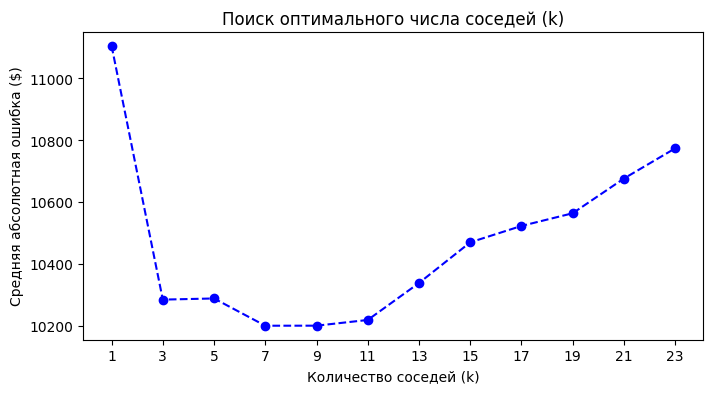

In [8]:
errors = []
k_values = range(1, 25, 2)

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    errors.append(mean_absolute_error(y_test, y_pred))

plt.figure(figsize=(8, 4))
plt.plot(k_values, errors, marker="o", linestyle="dashed", color="blue")
plt.title("Поиск оптимального числа соседей (k)")
plt.xlabel("Количество соседей (k)")
plt.ylabel("Средняя абсолютная ошибка ($)")
plt.xticks(k_values)
plt.show()

**Вывод:** при малых k ошибка максимальна — модель ориентируется на 1–2 ближайших автомобиля и переобучается. При росте k ошибка снижается и достигает минимума в районе k = 5, после чего снова начинает расти из-за недообучения. Оптимум найден в средней зоне, где MAE минимальна, — это значение используется далее при сравнении метрик расстояния.

# 6. Сравнение метрик расстояния

С оптимальным значением k = 5, найденным на предыдущем шаге, обучаются две модели kNN: с Евклидовым (p = 2) и Манхэттенским (p = 1) расстоянием. Для каждой считаются MAE и R² на тестовой выборке. Модель с меньшей ошибкой используется далее для визуализации.

In [9]:
best_k = 5

knn_euclidean = KNeighborsRegressor(n_neighbors=best_k, p=2)
knn_euclidean.fit(X_train, y_train)
y_pred_euc = knn_euclidean.predict(X_test)

knn_manhattan = KNeighborsRegressor(n_neighbors=best_k, p=1)
knn_manhattan.fit(X_train, y_train)
y_pred_man = knn_manhattan.predict(X_test)

print("=== Сравнение метрик расстояния ===")
print(f"Евклидово расстояние (p=2): MAE = ${mean_absolute_error(y_test, y_pred_euc):.2f} | R2 = {r2_score(y_test, y_pred_euc):.2f}")
print(f"Манхэттенское расстояние (p=1): MAE = ${mean_absolute_error(y_test, y_pred_man):.2f} | R2 = {r2_score(y_test, y_pred_man):.2f}")

=== Сравнение метрик расстояния ===
Евклидово расстояние (p=2): MAE = $10289.87 | R2 = 0.67
Манхэттенское расстояние (p=1): MAE = $9811.28 | R2 = 0.73


**Вывод:** обе модели kNN показали высокое качество, но Манхэттенское расстояние оказалось лучше: MAE ≈ 9 811 и R² ≈ 0,73 против MAE ≈ 10 290 и R² ≈ 0,67 у Евклидова. Причина в том, что после One-Hot-кодирования в выборке много бинарных признаков (марка, топливо, коробка передач, ДТП), и сумма модулей разниц по таким столбцам устойчивее, чем сумма квадратов. Поэтому для финальной визуализации используется модель с Манхэттенским расстоянием как показавшая меньшую ошибку и более высокий R².

# 7. Визуализация результатов kNN с Манхэттенским расстоянием

Для наглядной оценки качества лучшей модели строится график «реальные цены vs предсказанные цены». На график добавляется идеальная диагональ: чем ближе точки к ней, тем точнее модель.

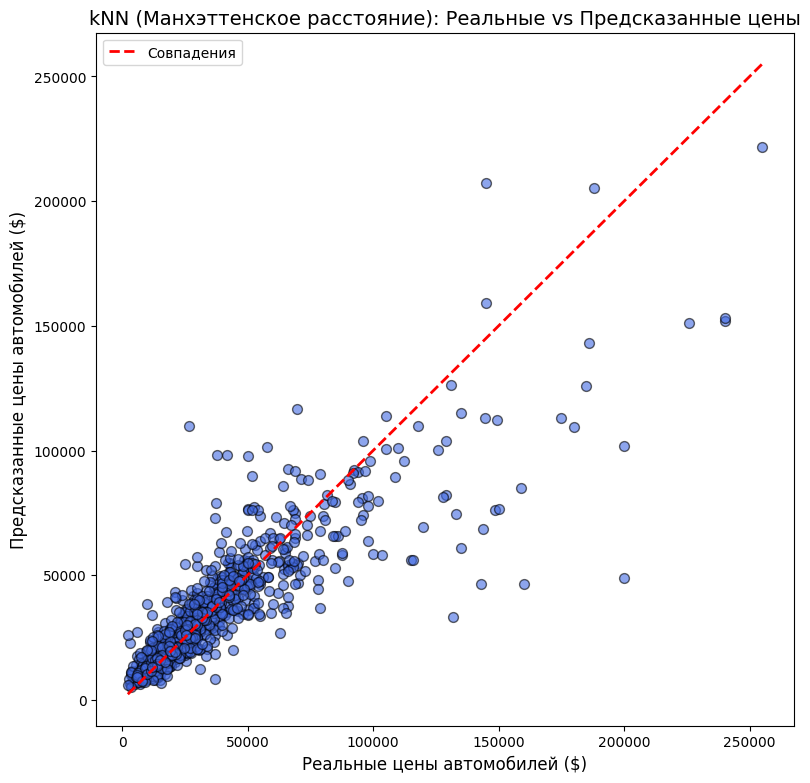

In [11]:
plt.figure(figsize=(9, 9))

plt.scatter(y_test, y_pred_man, alpha=0.6, color="royalblue", edgecolor="k", s=50)

max_val = max(y_test.max(), y_pred_man.max())
min_val = min(y_test.min(), y_pred_man.min())

plt.plot(
    [min_val, max_val], [min_val, max_val], "r--", lw=2, label="Совпадения"
)

plt.title("kNN (Манхэттенское расстояние): Реальные vs Предсказанные цены", fontsize=14)
plt.xlabel("Реальные цены автомобилей ($)", fontsize=12)
plt.ylabel("Предсказанные цены автомобилей ($)", fontsize=12)
plt.legend()
plt.show()

**Вывод:** основная масса точек группируется вдоль диагонали — модель хорошо различает дешёвые и дорогие автомобили. Разброс точек вокруг диагонали умеренный, что согласуется с высоким R² ≈ 0,73. Наиболее проблемными остаются автомобили средней ценовой категории (20–40 тыс. $): там точек максимально много, и модель иногда путает соседние ценовые уровни.

# 8. Финальный вывод

В ходе работы был рассмотрен и загружен датасет о подержанных автомобилях. На этапе подготовки данных были удалены дорогие автомобили — они сильно искажали модель, так как единичные экземпляры за миллионы долларов сдвигали предсказания в сторону среднего. Дополнительно из столбца *engine* были извлечены числовые признаки *hp* и *engine_vol*, что дало модели информацию о мощности и объёме двигателя.

Из двух вариантов kNN лучше показал себя метод с Манхэттенским расстоянием: MAE ≈ 9 811, R² ≈ 0,73 (против MAE ≈ 10 290 и R² ≈ 0,67 у Евклидова). Это объясняется тем, что после One-Hot-кодирования в выборке много бинарных признаков, и сумма модулей разниц по ним устойчивее, чем сумма квадратов. Качество модели выросло в разы по сравнению с первоначальным вариантом — основной эффект дали очистка выбросов и добавление числовых признаков. Тем не менее R² ≈ 0,73 означает, что около 27 % разброса цен модель не объясняет. 